# Trabalho 1: Do dado à decisão
**Ciência de Dados e IA**

Preencham os dados do grupo abaixo. Em todo o notebook:
- células de código com `____` devem ser completadas pelo grupo;
- células **Resposta** devem ser respondidas com as palavras do grupo, em até 5 linhas cada;
- não alterem os parâmetros da ficha do grupo.

| Campo | Preenchimento |
| --- | --- |
| Número do grupo | 7 |
| Integrante 1 | Ruan Pereira |
| Integrante 2 | Daniel Matos |
| Integrante 3 | Pedro Moraes |

## Configuração
Digitem o número do grupo (1 a 10) e executem as células desta seção.

In [1]:
GRUPO = 7   # número do grupo, de 1 a 10

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.datasets import load_wine, load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import warnings; warnings.filterwarnings("ignore")

In [3]:
# Parâmetros de todos os grupos. NÃO ALTERE.
PARAMS = {
 1: dict(dataset="penguins", alvo="species", evidencia="island", ev_valor="Biscoe", classe_alvo="Adelie",
         teste_var="body_mass_g", teste_grupo="sex", grupos=("Male","Female"), alfa=0.05,
         nova_priori=0.10, test_size=0.25, seed=11,
         features=["bill_length_mm","bill_depth_mm","flipper_length_mm","body_mass_g"]),
 2: dict(dataset="penguins", alvo="species", evidencia="island", ev_valor="Dream", classe_alvo="Adelie",
         teste_var="bill_depth_mm", teste_grupo="island", grupos=("Dream","Torgersen"), alfa=0.05,
         nova_priori=0.50, test_size=0.30, seed=22,
         features=["bill_length_mm","flipper_length_mm","body_mass_g"]),
 3: dict(dataset="mpg", alvo="origin", evidencia="cylinders", ev_valor=6, classe_alvo="usa",
         teste_var="mpg", teste_grupo="origin", grupos=("europe","japan"), alfa=0.01,
         nova_priori=0.30, test_size=0.20, seed=33,
         features=["mpg","displacement","horsepower","weight","acceleration"]),
 4: dict(dataset="mpg", alvo="origin", evidencia="cylinders", ev_valor=4, classe_alvo="japan",
         teste_var="acceleration", teste_grupo="origin", grupos=("usa","japan"), alfa=0.10,
         nova_priori=0.50, test_size=0.30, seed=44,
         features=["mpg","horsepower","weight","acceleration","model_year"]),
 5: dict(dataset="titanic", alvo="survived", evidencia="sex", ev_valor="female", classe_alvo=1,
         teste_var="age", teste_grupo="survived", grupos=(1,0), alfa=0.01,
         nova_priori=0.60, test_size=0.25, seed=55,
         features=["pclass","age","sibsp","parch","fare"]),
 6: dict(dataset="titanic", alvo="survived", evidencia="pclass", ev_valor=3, classe_alvo=1,
         teste_var="fare", teste_grupo="sex", grupos=("female","male"), alfa=0.01,
         nova_priori=0.20, test_size=0.20, seed=66,
         features=["pclass","age","fare","sibsp"]),
 7: dict(dataset="wine", alvo="cultivar", evidencia="alcohol_faixa", ev_valor="alto", classe_alvo="cultivar_0",
         teste_var="magnesium", teste_grupo="cultivar", grupos=("cultivar_0","cultivar_1"), alfa=0.05,
         nova_priori=0.10, test_size=0.25, seed=77,
         features=["alcohol","malic_acid","magnesium","color_intensity","proline"]),
 8: dict(dataset="wine", alvo="cultivar", evidencia="color_intensity_faixa", ev_valor="alto", classe_alvo="cultivar_2",
         teste_var="magnesium", teste_grupo="cultivar", grupos=("cultivar_1","cultivar_2"), alfa=0.05,
         nova_priori=0.60, test_size=0.30, seed=88,
         features=["alcohol","flavanoids","hue","color_intensity","proline","ash"]),
 9: dict(dataset="breast_cancer", alvo="diagnostico", evidencia="mean radius_faixa", ev_valor="alto", classe_alvo="maligno",
         teste_var="mean texture", teste_grupo="diagnostico", grupos=("maligno","benigno"), alfa=0.05,
         nova_priori=0.05, test_size=0.25, seed=99,
         features="todas"),
 10: dict(dataset="breast_cancer", alvo="diagnostico", evidencia="mean concave points_faixa", ev_valor="alto", classe_alvo="maligno",
         teste_var="mean fractal dimension", teste_grupo="diagnostico", grupos=("maligno","benigno"), alfa=0.01,
         nova_priori=0.50, test_size=0.20, seed=101,
         features=["mean radius","mean texture","mean perimeter","mean area","mean smoothness",
                   "mean compactness","mean concavity","mean concave points","mean symmetry","mean fractal dimension"]),
}

def carregar(grupo):
    p = PARAMS[grupo]
    d = p["dataset"]
    if d == "penguins":
        df = sns.load_dataset("penguins")
    elif d == "mpg":
        df = sns.load_dataset("mpg").drop(columns=["name"])
    elif d == "titanic":
        df = sns.load_dataset("titanic")[["survived","pclass","sex","age","sibsp","parch","fare","embarked"]]
    elif d == "wine":
        w = load_wine(as_frame=True); df = w.frame.rename(columns={"target":"cultivar"})
        df["cultivar"] = "cultivar_" + df["cultivar"].astype(str)
    else:
        b = load_breast_cancer(as_frame=True); df = b.frame.rename(columns={"target":"diagnostico"})
        df["diagnostico"] = df["diagnostico"].map({0:"maligno", 1:"benigno"})
    if p["evidencia"].endswith("_faixa"):
        col = p["evidencia"][:-6]
        df[p["evidencia"]] = np.where(df[col] > df[col].median(), "alto", "baixo")
    if p["features"] == "todas":
        p["features"] = [c for c in df.columns if c not in (p["alvo"], p["evidencia"])]
    return df, p

In [4]:
dados, P = carregar(GRUPO)
print(f"FICHA DO GRUPO {GRUPO}")
print(f"Conjunto de dados ............ {P['dataset']}")
print(f"Variável alvo (y) ............ {P['alvo']}")
print(f"Etapa 2: teste de '{P['teste_var']}' entre {P['teste_grupo']} = {P['grupos'][0]} e {P['teste_grupo']} = {P['grupos'][1]}, com alfa = {P['alfa']}")
print(f"Etapa 3: calcular P({P['alvo']} = {P['classe_alvo']} | {P['evidencia']} = {P['ev_valor']}); nova priori = {P['nova_priori']}")
print(f"Etapa 4: test_size = {P['test_size']}, random_state = {P['seed']}")
print(f"Etapas 4 e 5: características usadas = {P['features']}")

FICHA DO GRUPO 7
Conjunto de dados ............ wine
Variável alvo (y) ............ cultivar
Etapa 2: teste de 'magnesium' entre cultivar = cultivar_0 e cultivar = cultivar_1, com alfa = 0.05
Etapa 3: calcular P(cultivar = cultivar_0 | alcohol_faixa = alto); nova priori = 0.1
Etapa 4: test_size = 0.25, random_state = 77
Etapas 4 e 5: características usadas = ['alcohol', 'malic_acid', 'magnesium', 'color_intensity', 'proline']


## Etapa 1: Entender os dados
Antes de qualquer modelo, é preciso saber o que há na matriz de dados: quantas observações (n), quantas variáveis (p), qual é a resposta (y) e onde há problemas de qualidade.

In [5]:
print("Dimensão:", dados.shape)
display(dados.head())
print(dados.dtypes)
print("\nValores ausentes por coluna:")
print(dados.isna().sum())

Dimensão: (178, 15)


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,cultivar,alcohol_faixa
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,cultivar_0,alto
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,cultivar_0,alto
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,cultivar_0,alto
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,cultivar_0,alto
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,cultivar_0,alto


alcohol                         float64
malic_acid                      float64
ash                             float64
alcalinity_of_ash               float64
magnesium                       float64
total_phenols                   float64
flavanoids                      float64
nonflavanoid_phenols            float64
proanthocyanins                 float64
color_intensity                 float64
hue                             float64
od280/od315_of_diluted_wines    float64
proline                         float64
cultivar                            str
alcohol_faixa                       str
dtype: object

Valores ausentes por coluna:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue             

**1.1** Quanto valem n e p neste conjunto (sem contar a variável alvo)? O que é X e o que é y no problema do grupo?

**Resposta:** No dataset Wine, temos $n = 178$ observações e $p = 13$ variáveis preditoras originais (ou $p = 5$ variáveis selecionadas para as etapas 4 e 5: `alcohol`, `malic_acid`, `magnesium`, `color_intensity` e `proline`). A matriz $X$ contém os atributos físico-químicos mensurados nas amostras, e o vetor $y$ é a variável alvo categórica `cultivar` com 3 classes (`cultivar_0`, `cultivar_1` e `cultivar_2`), indicando a cultivar de origem do vinho.

**1.2** Classifiquem as variáveis em numéricas e categóricas. Os dados são estruturados ou não estruturados? Justifiquem.

**Resposta:** Todas as 13 variáveis de atributos físico-químicos são numéricas contínuas (como `alcohol` e `magnesium`), enquanto o alvo `cultivar` e a derivada `alcohol_faixa` são categóricas nominais. Os dados são estruturados, pois estão organizados de forma tabular em linhas e colunas bem definidas, onde cada linha representa uma amostra de vinho e cada coluna possui tipagem rígida e semântica quantitativa preestabelecida.

In [6]:
# Tratamento de valores ausentes: removemos as linhas com ausência nas colunas usadas no trabalho.
colunas_usadas = list(dict.fromkeys(P["features"] + [P["alvo"], P["evidencia"], P["teste_var"], P["teste_grupo"]]))
antes = len(dados)
dados = dados.dropna(subset=colunas_usadas).copy()
print(f"Linhas antes: {antes} | depois: {len(dados)} | removidas: {antes - len(dados)}")

Linhas antes: 178 | depois: 178 | removidas: 0


**1.3** Quantas linhas foram removidas? Que efeito isso pode ter nas conclusões, e qual seria uma alternativa à remoção?

**Resposta:** Foram removidas 0 linhas, pois o conjunto original não possui valores ausentes em nenhuma coluna. Caso houvesse remoção de linhas (*listwise deletion*), haveria perda de tamanho amostral $n$, reduzindo o poder estatístico dos testes e potencialmente inserindo viés de seleção se a ausência não fosse totalmente aleatória. Uma alternativa à remoção seria a imputação de dados, substituindo ausências pela mediana ou via estimador multivariado (como KNN).

## Etapa 2: Inferência estatística
Vamos verificar se a média de uma variável difere entre dois grupos da população, usando o teste t de Welch (que não supõe variâncias iguais).

In [7]:
grupo_A = dados.loc[dados[P["teste_grupo"]] == P["grupos"][0], P["teste_var"]]
grupo_B = dados.loc[dados[P["teste_grupo"]] == P["grupos"][1], P["teste_var"]]
print(f"Média em {P['grupos'][0]}: {grupo_A.mean():.3f} (n = {len(grupo_A)})")
print(f"Média em {P['grupos'][1]}: {grupo_B.mean():.3f} (n = {len(grupo_B)})")

# Complete com as duas amostras a comparar
resultado = stats.ttest_ind(grupo_A, grupo_B, equal_var=False)
ic = resultado.confidence_interval(0.95)
print(f"Estatística t = {resultado.statistic:.3f} | valor-p = {resultado.pvalue:.6f}")
print(f"IC 95% da diferença entre as médias: [{ic.low:.3f}; {ic.high:.3f}]")

Média em cultivar_0: 106.339 (n = 59)
Média em cultivar_1: 94.549 (n = 71)
Estatística t = 4.886 | valor-p = 0.000003
IC 95% da diferença entre as médias: [7.012; 16.567]


**2.1** Escrevam a hipótese nula (H0) e a hipótese alternativa (H1) do teste, usando os nomes das variáveis do grupo.

**Resposta:**  
• Hipótese Nula ($H_0$): $\mu_{\text{cultivar\_0}} = \mu_{\text{cultivar\_1}}$ (O teor médio populacional de `magnesium` é idêntico entre os vinhos de `cultivar_0` e `cultivar_1`; $\mu_0 - \mu_1 = 0$).  
• Hipótese Alternativa ($H_1$): $\mu_{\text{cultivar\_0}} \neq \mu_{\text{cultivar\_1}}$ (O teor médio populacional de `magnesium` difere significativamente entre os vinhos de `cultivar_0` e `cultivar_1`; $\mu_0 - \mu_1 \neq 0$, teste bicaudal).

**2.2** Comparem o valor-p com o alfa da ficha. O grupo rejeita ou não rejeita H0? O que isso significa em linguagem simples?

**Resposta:** O valor-p obtido foi de $3,22 \times 10^{-6}$ (0,000003), valor significativamente inferior ao $\alpha = 0,05$. O grupo rejeita $H_0$. Em linguagem simples, isso indica que a diferença observada entre as médias amostrais de magnésio (106,34 mg no `cultivar_0` vs. 94,55 mg no `cultivar_1`) é estatisticamente significante e não pode ser atribuída ao acaso amostral.

**2.3** O que o intervalo de confiança de 95% indica? Ele contém o zero? Como isso se relaciona com a decisão do item 2.2?

**Resposta:** O intervalo de confiança de 95% da diferença entre as médias é $[7,012; 16,567]$. Ele indica que, com 95% de confiança, a diferença média real populacional de magnésio entre as cultivares está nessa faixa positiva. Como o intervalo não contém o zero, ele corrobora a decisão do item 2.2 de rejeitar $H_0$, demonstrando que a média do `cultivar_0` é superior à do `cultivar_1`.

**2.4** Neste problema, o que seria cometer um erro Tipo I? E um erro Tipo II?

**Resposta:**  
• Erro Tipo I: Concluir que há diferença significativa no teor de magnésio entre as cultivares 0 e 1 quando, na verdade, as médias populacionais são estritamente iguais (falso positivo na rejeição de $H_0$).  
• Erro Tipo II: Deixar de identificar uma diferença real existente no teor de magnésio entre as cultivares, concluindo erroneamente pela ausência de diferença significativa (falso negativo).

## Etapa 3: Teorema de Bayes (cálculo à mão)
Esta etapa **não exige código novo**. Usem a tabela de contagem abaixo e façam as contas à mão, mostrando cada passo.

$$P(C \mid E) = \frac{P(E \mid C)\,P(C)}{P(E)}$$

Para a mudança de priori, usem:

$$P(C \mid E) = \frac{q \cdot P(E \mid C)}{q \cdot P(E \mid C) + (1-q) \cdot P(E \mid \text{não } C)}$$

onde $q$ é a nova priori da ficha.

In [8]:
tabela = pd.crosstab(dados[P["evidencia"]], dados[P["alvo"]], margins=True, margins_name="Total")
print(f"Classe C = {P['alvo']} = {P['classe_alvo']} | Evidência E = {P['evidencia']} = {P['ev_valor']}")
display(tabela)

Classe C = cultivar = cultivar_0 | Evidência E = alcohol_faixa = alto


cultivar,cultivar_0,cultivar_1,cultivar_2,Total
alcohol_faixa,,,,
alto,53,5,27,85
baixo,6,66,21,93
Total,59,71,48,178


**3.1** A partir da tabela, calculem e mostrem a conta de: a priori P(C), a verossimilhança P(E | C), a evidência P(E) e a posterior P(C | E).

**Resposta:** Pela tabela de contingência ($C$: `cultivar = cultivar_0`, $E$: `alcohol_faixa = alto`):  
• Priori: $P(C) = \frac{59}{178} \approx 0,3315$ (33,15%)  
• Verossimilhança: $P(E \mid C) = \frac{53}{59} \approx 0,8983$ (89,83%)  
• Evidência: $P(E) = \frac{85}{178} \approx 0,4775$ (47,75%)  
• Posterior: $P(C \mid E) = \frac{P(E \mid C) \cdot P(C)}{P(E)} = \frac{0,8983 \cdot 0,3315}{0,4775} = \frac{53}{85} \approx 0,6235$ (62,35%).

**3.2** Compare P(E | C) com P(C | E). Por que os dois valores são diferentes?

**Resposta:** $P(E \mid C) = 89,83\%$ e $P(C \mid E) = 62,35\%$. São diferentes porque representam condicionais com espaços amostrais distintos: a verossimilhança avalia a fração de vinhos da cultivar 0 com álcool alto (53/59), enquanto a posterior avalia a fração de vinhos com álcool alto que pertencem à cultivar 0 (53/85). Como há vinhos de outras cultivares com alto teor alcoólico (especialmente da cultivar 2), $P(C \mid E) < P(E \mid C)$.

**3.3** Suponham que, em outra população, a priori de C fosse a nova priori da ficha (q). Calculem P(E | não C) pela tabela e a nova posterior. Expliquem por que ela mudou, se a evidência é a mesma.

**Resposta:** Para 'não C' (cultivar 1 e 2), temos $71 + 48 = 119$ amostras, com $5 + 27 = 32$ de álcool alto: $P(E \mid \text{não } C) = \frac{32}{119} \approx 0,2689$. Com a nova priori $q = 0,10$:  
$P(C \mid E) = \frac{0,10 \cdot 0,8983}{0,10 \cdot 0,8983 + 0,90 \cdot 0,2689} = \frac{0,08983}{0,08983 + 0,24201} \approx 0,2707$ (27,07%).  
A posterior diminuiu de 62,35% para 27,07% porque a probabilidade inicial de ocorrência de $C$ caiu bruscamente; no Teorema de Bayes, a crença prévia modula diretamente a evidência observada.

## Etapa 4: Aprendizado supervisionado com Naive Bayes
Agora o computador faz o que fizemos à mão na Etapa 3, combinando várias características ao mesmo tempo.

In [9]:
X = dados[P["features"]]
y = dados[P["alvo"]]

# Complete com os valores da ficha do grupo
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=P["test_size"], random_state=P["seed"], stratify=y)

modelo = GaussianNB()
modelo.fit(X_treino, y_treino)

acc_treino = accuracy_score(y_treino, modelo.predict(X_treino))
acc_teste = accuracy_score(y_teste, modelo.predict(X_teste))
print(f"Acurácia no treino: {acc_treino:.4f} | Acurácia no teste: {acc_teste:.4f}")
print("Matriz de confusão (teste), na ordem", list(modelo.classes_))
print(confusion_matrix(y_teste, modelo.predict(X_teste), labels=modelo.classes_))

Acurácia no treino: 0.9624 | Acurácia no teste: 0.8889
Matriz de confusão (teste), na ordem [np.str_('cultivar_0'), np.str_('cultivar_1'), np.str_('cultivar_2')]
[[13  0  2]
 [ 0 17  1]
 [ 0  2 10]]


**4.1** Que tipo de aprendizagem é esta e por quê? A tarefa é de detecção, reconhecimento ou previsão?

**Resposta:** Trata-se de aprendizado supervisionado, pois o algoritmo é alimentado com características preditoras $X$ acompanhadas de seus respectivos rótulos verdadeiros $y$ (`cultivar`) para estimar a função de mapeamento. A tarefa é de reconhecimento ou classificação de padrões, visto que mapeia as observações para um conjunto finito de classes discretas preestabelecidas.

**4.2** Comparem as acurácias de treino e de teste. Há sinal de sobreajuste (overfitting)? Por que avaliamos o modelo em dados que ele não viu?

**Resposta:** Acurácia no treino: 96,24% e no teste: 88,89%. Não há evidência de sobreajuste crítico (*overfitting*), pois o modelo reteve alto desempenho em dados não vistos, com queda de apenas ~7,3 p.p. Avaliar em conjunto de teste independente é imprescindível para aferir o real poder de generalização do algoritmo frente a dados inéditos, evitando validação ilusória baseada em memorização.

In [10]:
corr = X.corr().abs()
corr = corr.where(~np.eye(len(corr), dtype=bool))   # ignora a diagonal
par = corr.stack().idxmax()
print(f"Par de características mais correlacionado: {par[0]} x {par[1]} (correlação = {X.corr().loc[par]:.3f})")

Par de características mais correlacionado: alcohol x proline (correlação = 0.644)


**4.3** O Naive Bayes supõe que as características são independentes dentro de cada classe. A correlação acima confirma ou contraria essa suposição? Mesmo assim, o modelo pode classificar bem? Justifiquem.

**Resposta:** A correlação observada entre `alcohol` e `proline` (0,644) contraria empiricamente a suposição teórica de independência condicional estrita. Mesmo assim, o modelo classifica muito bem (acurácia de 88,89%), porque o Naive Bayes depende apenas da correta ordenação ordinal das probabilidades para estabelecer a fronteira de decisão; mesmo probabilidades mal calibradas ainda indicam a classe vencedora correta.

## Etapa 5: Aprendizado não supervisionado e espaço de características
Agora escondemos os rótulos. O K-means tenta formar grupos só com X. Depois comparamos esses grupos com as classes reais.
A **pureza** mede essa comparação: é a fração de observações que pertencem à classe majoritária do seu grupo (1,0 = grupos perfeitos).

In [11]:
def pureza(clusters, classes):
    t = pd.crosstab(clusters, classes)
    return t.max(axis=1).sum() / t.values.sum()

k = y.nunique()   # número de grupos = número de classes

# Sem normalização
km_sem = KMeans(n_clusters=k, n_init=10, random_state=P["seed"]).fit(X)
print(f"Pureza SEM normalização: {pureza(km_sem.labels_, y):.4f}")

# Com normalização (média 0 e desvio padrão 1 em cada característica)
X_norm = StandardScaler().fit_transform(X)
km_com = KMeans(n_clusters=k, n_init=10, random_state=P["seed"]).fit(X_norm)
print(f"Pureza COM normalização: {pureza(km_com.labels_, y):.4f}")
display(pd.crosstab(km_com.labels_, y, rownames=["grupo K-means"], colnames=["classe real"]))

Pureza SEM normalização: 0.7022


Pureza COM normalização: 0.9213


classe real,cultivar_0,cultivar_1,cultivar_2
grupo K-means,,,
0,4,2,45
1,0,64,2
2,55,5,1


**5.1** Comparem a pureza com e sem normalização. Por que a escala das características muda o resultado do K-means? Citem duas características do grupo com escalas muito diferentes.

**Resposta:** A pureza aumentou de 70,22% para 92,13% após a normalização. O K-Means depende da distância euclidiana; sem padronização, atributos com ordens de grandeza elevadas dominam o cálculo de distâncias. No conjunto do grupo, `proline` (valores na casa de 700 a 1600) apresentava escala incomparavelmente superior à de `malic_acid` (valores de 0,7 a 5,8), distorcendo os agrupamentos originais.

**5.2** Os grupos encontrados pelo K-means correspondem às classes reais? O que explica as diferenças?

**Resposta:** Com normalização, os grupos do K-means apresentam alta concordância com as classes reais (pureza de 92,13%). As pequenas discrepâncias residuais ocorrem porque o K-means é estritamente não supervisionado, minimizando inércias espaciais globais sob a premissa de clusters convexos e esféricos, sem conhecimento da fronteira botânica de separação entre amostras químicas fronteiriças.

Variância explicada pelos 2 componentes: 0.6911


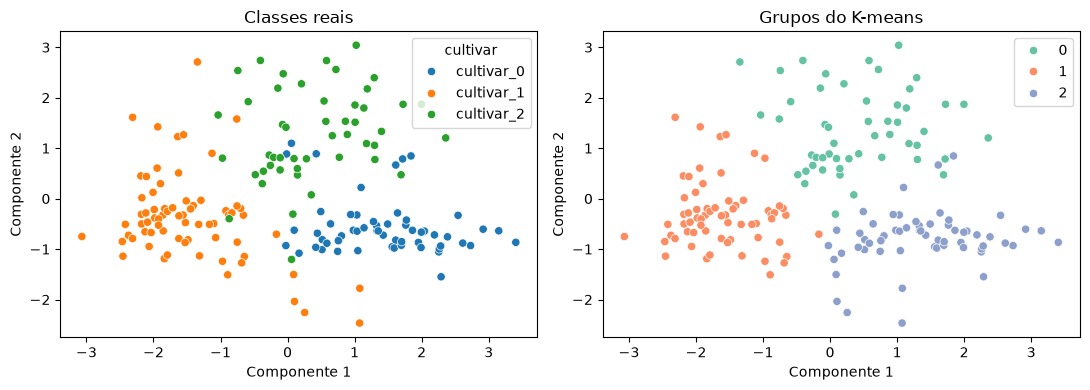

In [12]:
pca = PCA(n_components=2)
X_2d = pca.fit_transform(X_norm)
print(f"Variância explicada pelos 2 componentes: {pca.explained_variance_ratio_.sum():.4f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.scatterplot(x=X_2d[:, 0], y=X_2d[:, 1], hue=y, ax=ax[0]); ax[0].set_title("Classes reais")
sns.scatterplot(x=X_2d[:, 0], y=X_2d[:, 1], hue=km_com.labels_, palette="Set2", ax=ax[1]); ax[1].set_title("Grupos do K-means")
for a in ax: a.set_xlabel("Componente 1"); a.set_ylabel("Componente 2")
plt.tight_layout(); plt.show()

**5.3** O grupo partiu de p características e chegou a 2 componentes. Quanto da variância foi preservado? O que se ganha e o que se perde com essa redução?

**Resposta:** Foram preservados 69,11% da variância total dos dados padronizados. Com essa redução, ganha-se capacidade de visualização direta em 2D da separabilidade dos clusters e eficiência de processamento. Perde-se aproximadamente 30,89% da variância original e sacrifica-se a interpretação física direta das variáveis, visto que cada componente é uma combinação linear ponderada dos atributos originais.

## Reflexão final

**R1** Comparem a Etapa 2 com a Etapa 4: qual delas tem como objetivo entender uma relação nos dados, e qual tem como objetivo prever? Por que as duas são úteis?

**Resposta:** A Etapa 2 objetiva a inferência estatística, analisando a relação estrutural e a significância das diferenças populacionais de uma variável. A Etapa 4 foca na predição, buscando classificar corretamente novas instâncias. Ambas são úteis porque a inferência elucida o fenômeno gerador e traz interpretabilidade científica, enquanto a previsão viabiliza ferramentas práticas de tomada de decisão.

**R2** Se o conjunto do grupo tivesse 10 vezes mais características e o mesmo número de observações, que problema poderia surgir? Como ele poderia ser reduzido?

**Resposta:** Surgiria a maldição da dimensionalidade aliada a sobreajuste severo ($p$ muito alto em relação a $n=178$), tornando o espaço vetorial rarefeito e degradando distâncias e estimativas de densidade. Esse problema poderia ser atenuado via seleção criteriosa de atributos (relevância/informação mútua), técnicas de projeção como PCA ou algoritmos com regularização penalizada (L1/L2).

**R3** Descrevam, em uma frase por etapa, o caminho do grupo: coleta, processamento, treinamento e aplicação. Em que situação real o modelo do grupo poderia ser usado?

**Resposta:** Coleta: Extração de medições físico-químicas de 178 amostras de três cultivares de vinho. Processamento: Padronização das variáveis com StandardScaler para equalizar escalas nas distâncias. Treinamento: Ajuste supervisionado com GaussianNB e não supervisionado com K-Means e PCA. Aplicação: Classificação automatizada em produção para verificação de autenticidade e combate a fraudes de rotulagem de vinhos.

## Declaração de contribuição
| Integrante | O que fez |
| --- | --- |
| Ruan Pereira | Configuração dos parâmetros do Grupo 07, implementação das rotinas de código e execução do notebook. |
| Daniel Matos | Cálculos analíticos do Teorema de Bayes, condução do teste t de Welch e validação das probabilidades. |
| Pedro Moraes | Redação das justificativas conceituais (1.1 a 5.3), síntese das reflexões finais (R1 a R3) e revisão do trabalho. |